In [121]:
# Environment and path setup is handled in the next cell.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [122]:
import math
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Arquivos disponíveis em utils: ['pruning.py', 'utility_reset.py', 'filtered_paths.py', '__pycache__', 'region_checks.py', 'intersection_utils.py', 'point_generator.py', 'path_analysis.py', 'plotting.py', 'nextSteps.txt', 'test_paths_in_subregions.ipynb', 'testing_data_structures.ipynb', 'testing_points_in_subregions.ipynb', 'PiaNo.ipynb']


In [123]:
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *
#from predefined_networks import *
from tests import *

## Running the experiment

The original 2D pipeline, step by step: place N = 30 random sticks of length a = 0.70 (`generate_points`), find their intersections (`identify_intersections`), mark intersections with x < 0.1 as source and x > 0.9 as drain, trace the connected paths from each source node (`find_path`), and plot the sticks, intersections and percolating paths. The stored outputs predate the switch of `generate_points` to the `clip` boundary rule (2026-09-15), so a re-run draws a different network.

In [124]:
# Variáveis principais
a = 0.70
N = 30

points_1 = []
points_2 = []
angles = []
graph = [] #arestas
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

In [125]:
generate_points(N, points_1, points_2, angles, a)

In [126]:
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, a, N)

In [127]:
len(intersections_points)

60

In [128]:
boundary_condition_source = []
boundary_condition_drain = []

In [129]:
for i in range(len(intersections_points)):
  if intersections_points[i][0] < 0.1:
    boundary_condition_source.append(i)
  elif intersections_points[i][0] > 0.9:
    boundary_condition_drain.append(i)

In [130]:
print("Number of identified intersection points =", len(intersections_points))
print("In the source contact region =", len(boundary_condition_source))
print("In the drain contact region =", len(boundary_condition_drain))
print(boundary_condition_source)

Number of identified intersection points = 60
In the source contact region = 3
In the drain contact region = 4
[3, 42, 53]


In [131]:
path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc = [], [], [], []

In [132]:
for i in boundary_condition_source:
  do_not_check = 0
  number_path = len(all_connected_nodes)
  for k in range(0,number_path):
    if i in all_connected_nodes[k]:
      do_not_check = 1
  if do_not_check == 0:
    print(f"Path number = {number_path}")
    print(f"node = {i}")
    start_node = i
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, start_node)
    path_nodes.append(nodes)
    path_pairs_of_lines.append(pair_of_lines)
    path_pairs_of_edges.append(pair_of_edges,)
    all_path_perc.append(path_perc)
  # print(f"All nodes = {all_connected_nodes}")
  # print(f"All lines = {pair_of_lines}")

Path number = 0
node = 3
valor de queue antes = deque([3])
valor de queue depois = deque([])
nós visitados {3}
valor de target edge = (2, 27)
valor de path_pairs_of_lines = [(2, 27)]
valor do i = 2
valor do current node = 3
valor da queue após append = deque([2])
valor do path_pairs_of_nodes[3, 2]
valor do path_pairs_of_lines = [(2, 27), (2, 15)]
valor do path_pairs_of_edges = [(3, 2)]
valor de queue antes = deque([2])
valor de queue depois = deque([])
nós visitados {2, 3}
valor de target edge = (2, 15)
valor do i = 5
valor do current node = 2
valor da queue após append = deque([5])
valor do path_pairs_of_nodes[3, 2, 5]
valor do path_pairs_of_lines = [(2, 27), (2, 15), (3, 15)]
valor do path_pairs_of_edges = [(3, 2), (2, 5)]
valor do i = 27
valor do current node = 2
valor da queue após append = deque([5, 27])
valor do path_pairs_of_nodes[3, 2, 5, 27]
valor do path_pairs_of_lines = [(2, 27), (2, 15), (3, 15), (10, 15)]
valor do path_pairs_of_edges = [(3, 2), (2, 5), (2, 27)]
valor do i 

In [133]:
print(path_nodes) #create list of the correspoding pairs of edges
print(path_pairs_of_lines) #check what it is
print(path_pairs_of_edges) #create list of the correspoding nodes
print(all_path_perc)

[[3, 2, 5, 27, 39, 40, 41, 4, 17, 26, 32, 20, 28, 36, 31, 33, 34, 35, 37, 38, 0, 9, 16, 23, 25, 10, 11, 12, 14, 18, 55, 19, 21, 22, 30, 51, 24, 29, 43, 47, 56, 44, 48, 1, 7, 13, 15, 57, 58, 59, 49, 50, 45, 46, 6, 8, 52, 54, 53, 42], [42, 53, 52, 6, 13, 7, 8, 14, 15, 45, 58, 4, 9, 10, 11, 12, 18, 33, 55, 43, 44, 46, 49, 59, 56, 57, 5, 17, 26, 32, 0, 16, 23, 31, 40, 21, 29, 30, 37, 47, 38, 48, 28, 51, 19, 20, 22, 34, 35, 36, 39, 50, 54, 2, 27, 41, 1, 24, 25, 3], [53, 42, 52, 6, 13, 7, 8, 14, 15, 45, 58, 4, 9, 10, 11, 12, 18, 33, 55, 43, 44, 46, 49, 59, 56, 57, 5, 17, 26, 32, 0, 16, 23, 31, 40, 21, 29, 30, 37, 47, 38, 48, 28, 51, 19, 20, 22, 34, 35, 36, 39, 50, 54, 2, 27, 41, 1, 24, 25, 3]]
[[(2, 27), (2, 15), (3, 15), (10, 15), (14, 15), (15, 0), (15, 16), (3, 6), (8, 3), (10, 3), (14, 3), (8, 10), (10, 28), (14, 10), (14, 0), (14, 6), (14, 8), (14, 9), (14, 11), (14, 12), (1, 0), (6, 0), (8, 0), (9, 0), (9, 16), (6, 11), (6, 12), (6, 28), (7, 6), (8, 6), (29, 6), (8, 9), (8, 11), (8, 13

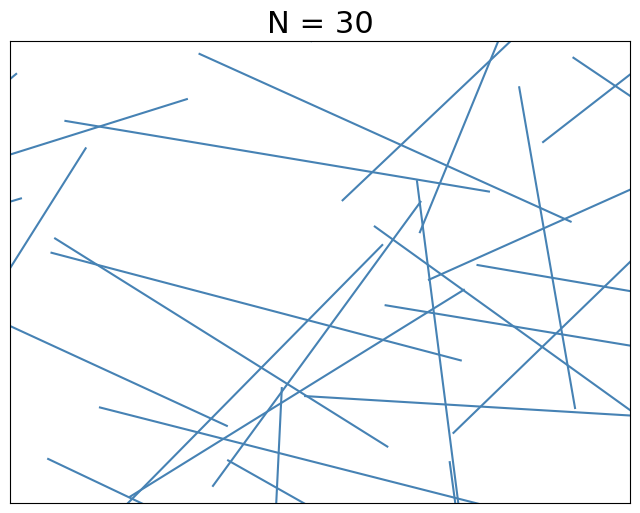

In [134]:
plot_lines(N, points_1, points_2)

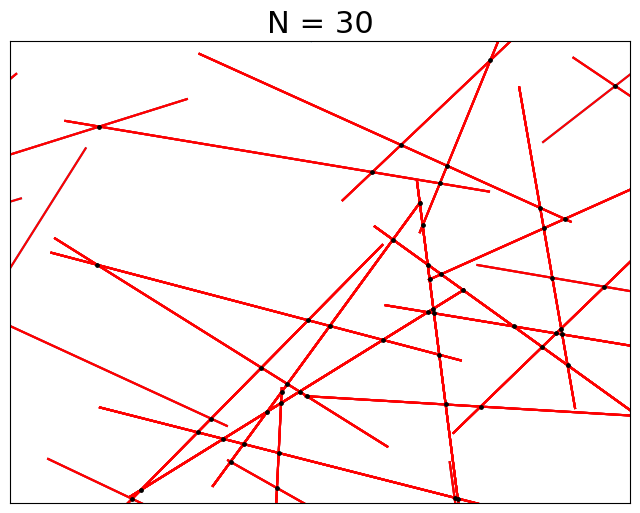

In [135]:
plot_lines_intersection(N, points_1, points_2, intersected_line_1, intersected_line_2, intersections_points)

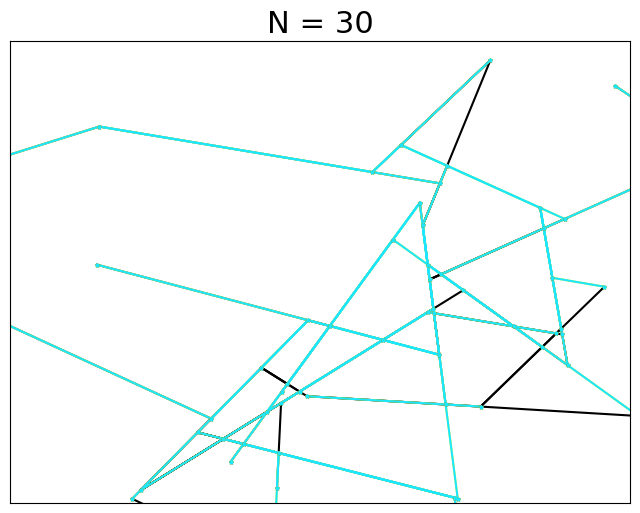

In [136]:
plot_only_paths(N, intersections_points, path_nodes, path_pairs_of_edges)

1
1
1


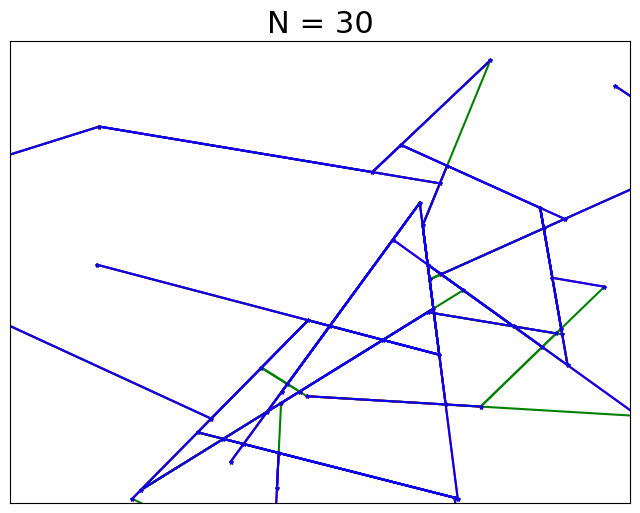

In [137]:
plot_percolating_paths(N, intersections_points, path_nodes, path_pairs_of_edges, all_path_perc)